# Read me

Este notebook usa K-Means para agrupar músicas a partir das features de áudio do Spotify e recomendar faixas próximas ao perfil das músicas de entrada.

**Objetivo:** identificar padrões sonoros que atravessem gêneros musicais.

**Abordagens**
- **Baseline:** K-Means nas features escaladas, sem redução de dimensionalidade.
- **PCA:** K-Means em espaços com dimensionalidade reduzida.

**Critérios de sucesso do MVP**
- **Similaridade sonora:** avaliar a compactação e a separação dos clusters.
- **Diversidade de gêneros:** verificar se os clusters atravessam diferentes gêneros musicais.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

from IPython.display import display

import joblib


sys.path.append("..")


from app.preprocessing.preprocessing import preprocessing


import app.spotify.spotify as spo


os.environ["LOKY_MAX_CPU_COUNT"] = "8"

In [2]:
n_clusters = 6
input_size = 5
output_size = 10


token = spo.get_access_token()

# Load data

In [3]:
df = pd.read_csv("../raw_data/spotify-tracks-dataset-detailed.csv")
df.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [4]:
print(f'Loaded {len(df)} rows')

Loaded 114000 rows


# Pre-process data

A função `preprocessing` reúne todas as etapas de preparação da base em um único lugar, para que o mesmo tratamento possa ser reaplicado de forma idêntica. As etapas, nesta ordem, são:

1. Remove o gênero comedy
2. Seleciona as colunas necessárias
3. Remove valores nulos
4. Remove duplicatas exatas
5. Preserva todos os gêneros de cada música (uma música pode aparecer em mais de um gênero) e mantém uma linha por música
6. Separa metadados e features
7. Escalona as features

**Scaling:** foi adotado o StandardScaler, que padroniza os valores para média 0 e desvio padrão 1. Como o K-Means é baseado em distância, features em escalas muito diferentes (como loudness e tempo, em relação às variáveis entre 0 e 1) dominariam o cálculo se não fossem padronizadas.

**Split Train Val Test:** não há divisão, porque a clusterização não é supervisionada. O scaler foi ajustado na base completa.

### Aplicação do Pre Processing

In [5]:
X_scaled, df_metadata, scaler, features = preprocessing(df)


audio_features = features

### Conferência dos Dados

Formato da matriz de features escaladas, metadados das músicas e a união dos dois.

In [6]:
X_scaled.shape

(80175, 8)

In [7]:
df_metadata.head()

,track_id,artists,track_name,genres
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,"[acoustic, j-pop, singer-songwriter, songwriter]"
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost - Acoustic,"[acoustic, chill]"
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,[acoustic]
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Can't Help Falling In Love,[acoustic]
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,[acoustic]


In [8]:
df_scaled = pd.DataFrame(X_scaled, columns=features)
df_scaled.head()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,valence,tempo
0,0.676937,-0.701560,0.323475,0.776805,-0.854487,-0.551196,0.960811,-1.182342
1,-0.815682,-1.857298,-1.792992,-0.041318,1.801679,-0.551182,-0.762295,-1.535282
2,-0.710732,-1.101171,-0.279443,-0.293991,-0.324922,-0.551199,-1.327690,-1.574441
3,-1.713586,-2.274147,-2.051270,-0.531946,1.745089,-0.550983,-1.239227,1.993142
4,0.338766,-0.772080,-0.268748,-0.332015,0.446492,-0.551199,-1.146917,-0.098203


In [9]:
df_final = pd.concat([df_metadata, df_scaled], axis=1)
df_final.head()

,track_id,artists,track_name,genres,danceability,energy,loudness,speechiness,acousticness,instrumentalness,valence,tempo
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,"[acoustic, j-pop, singer-songwriter, songwriter]",0.676937,-0.701560,0.323475,0.776805,-0.854487,-0.551196,0.960811,-1.182342
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost - Acoustic,"[acoustic, chill]",-0.815682,-1.857298,-1.792992,-0.041318,1.801679,-0.551182,-0.762295,-1.535282
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,[acoustic],-0.710732,-1.101171,-0.279443,-0.293991,-0.324922,-0.551199,-1.327690,-1.574441
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Can't Help Falling In Love,[acoustic],-1.713586,-2.274147,-2.051270,-0.531946,1.745089,-0.550983,-1.239227,1.993142
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,[acoustic],0.338766,-0.772080,-0.268748,-0.332015,0.446492,-0.551199,-1.146917,-0.098203


#### Observações sobre as features

- Energy, loudness e acousticness são fortemente correlacionadas e pesam como um único eixo de "intensidade" na distância dos algoritmos.
- Speechiness, instrumentalness e acousticness têm distribuição muito assimétrica, e loudness e duration têm outliers. Isso afeta o `StandardScaler`.

# Model selection

Nesta seção, comparamos o baseline com os espaços reduzidos pelo PCA para escolher o modelo final. As análises servem apenas à seleção; o modelo usado pelo recomendador é treinado novamente na seção **Train**.

## Funções Auxiliares de Avaliação

Os modelos são comparados pelas mesmas métricas:

- **Silhouette** (maior = melhor): avalia a separação dos clusters por amostragem. Nesta execução, foi usada uma única amostra fixa; por isso, o desvio-padrão exibido é zero e não representa a variabilidade da métrica.
- **Davies-Bouldin** (menor = melhor): avalia a similaridade entre os clusters.
- **Métricas no espaço original:** permitem comparar os modelos PCA e baseline no mesmo referencial.
- **Diversidade de gêneros:** considera o gênero dominante e a entropia de gêneros. O tamanho dos clusters também é analisado para evitar conclusões isoladas.

In [10]:
genres_exp = df_metadata["genres"].explode().rename("genre")


N_GENEROS = genres_exp.nunique()


def metricas_genero(labels):
    """Mede o quanto os clusters misturam gêneros (ligado ao critério de diversidade de gêneros do MVP).

    labels: pd.Series com o cluster de cada música (índice = índice de df_metadata). Ruído deve ser removido antes.
    - genero_dominante_pct: share do gênero mais comum em cada cluster, ponderado pelo tamanho do cluster (menor = mais misturado)
    - entropia_generos: entropia normalizada (0 a 1) da distribuição de gêneros em cada cluster, ponderada pelo tamanho (maior = mais diverso)
    """

    g = genres_exp.to_frame().join(labels.rename("cluster"), how="inner")


    tab = g.groupby(["cluster", "genre"]).size().unstack(fill_value=0)


    p = tab.div(tab.sum(axis=1), axis=0)
    peso = tab.sum(axis=1) / tab.values.sum()


    dominante = (p.max(axis=1) * peso).sum() * 100
    entropia = (-(p * np.log(p.where(p > 0, 1))).sum(axis=1) / np.log(N_GENEROS) * peso).sum()
    return {"genero_dominante_pct": dominante, "entropia_generos": entropia}



def perfil_clusters(labels, top_n=3):
    """Média das 8 features (escaladas) por cluster, tamanho do cluster e gêneros mais comuns. Ignora ruído (-1)."""

    labels = labels[labels != -1].rename("cluster")


    medias = df_scaled.loc[labels.index].groupby(labels).mean()


    g = genres_exp.to_frame().join(labels, how="inner")
    top = g.groupby("cluster")["genre"].agg(lambda s: ", ".join(s.value_counts().head(top_n).index))


    perfil = medias.copy()
    perfil["pct_musicas"] = labels.value_counts(normalize=True).sort_index() * 100
    perfil["top_generos"] = top
    return perfil


def plot_perfil(perfil, titulo, ax):
    """Heatmap com a média de cada feature (em desvios-padrão) por cluster."""
    medias = perfil[features]
    im = ax.imshow(medias.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
    ax.set_xticks(range(len(features)))
    ax.set_xticklabels(features, rotation=45, ha="right")
    ax.set_yticks(range(len(medias)))
    ax.set_yticklabels([f"c{c} ({p:.0f}%)" for c, p in zip(medias.index, perfil["pct_musicas"])])
    ax.set_title(titulo)
    return im




SEEDS_SILHOUETTE = [42]
TAMANHO_AMOSTRA_SIL = 2000


def silhouette_amostrado(X_modelo, labels):
    """Silhouette calculado em uma amostra para reduzir o custo da varredura."""

    notas = [
        silhouette_score(X_modelo, labels, sample_size=TAMANHO_AMOSTRA_SIL, random_state=s)
        for s in SEEDS_SILHOUETTE
    ]
    return np.mean(notas), np.std(notas)




modelos_kmeans = {}


def varrer_k(X_modelo, nome, ks=range(2, 16)):
    """Treina o K-Means para cada k e retorna inertia (elbow), silhouette e Davies-Bouldin. Guarda os clusters em modelos_kmeans."""
    linhas = []
    for k in ks:

        km = KMeans(n_clusters=k, n_init=5, random_state=42)
        labels = km.fit_predict(X_modelo)
        modelos_kmeans[(nome, k)] = labels


        sil_media, sil_std = silhouette_amostrado(X_modelo, labels)
        linhas.append({
            "espaco": nome,
            "k": k,
            "inertia": km.inertia_,
            "silhouette": sil_media,
            "silhouette_std": sil_std,
            "davies_bouldin": davies_bouldin_score(X_modelo, labels),
        })
        print(f"{nome} | K={k} | Silhouette={sil_media:.4f} (±{sil_std:.4f})")
    return pd.DataFrame(linhas)


def plot_varredura(res, titulo):
    """Plota Elbow, Silhouette (média ± desvio) e Davies-Bouldin para cada espaço da varredura."""
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    for nome, d in res.groupby("espaco", sort=False):
        axes[0].plot(d["k"], d["inertia"], marker="o", label=nome)
        axes[1].errorbar(d["k"], d["silhouette"], yerr=d["silhouette_std"], marker="o", capsize=2, label=nome)
        axes[2].plot(d["k"], d["davies_bouldin"], marker="o", label=nome)
    axes[0].set_title("Elbow Method")
    axes[0].set_ylabel("Within-Cluster Sums of Squares")
    axes[1].set_title("Silhouette (amostra)")
    axes[2].set_title("Davies-Bouldin (menor = melhor)")
    for ax in axes:
        ax.set_xlabel("Number of clusters")
        ax.grid(alpha=0.3)
    axes[1].legend()
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()



def comparar_kmeans(espacos, ks, res):
    """Reúne silhouette, Davies-Bouldin, tamanho dos clusters e métricas de gênero dos modelos treinados na varredura de k.

    Reaproveita os clusters (modelos_kmeans) e as métricas do espaço do modelo (res), sem treinar de novo.
    """
    linhas = []
    for nome, X_modelo in espacos.items():
        for k in ks:

            labels = modelos_kmeans[(nome, k)]
            r = res[(res["espaco"] == nome) & (res["k"] == k)].iloc[0]
            sil, db = r["silhouette"], r["davies_bouldin"]


            serie = pd.Series(labels, index=df_metadata.index)
            tamanhos = serie.value_counts(normalize=True) * 100


            if nome == NOME_BASELINE:
                sil_8d, db_8d = sil, db
            else:
                sil_8d, _ = silhouette_amostrado(X_base, labels)
                db_8d = davies_bouldin_score(X_base, labels)


            linhas.append({
                "espaco": nome,
                "k": k,
                "silhouette": sil,
                "silhouette_8d": sil_8d,
                "davies_bouldin": db,
                "davies_bouldin_8d": db_8d,
                "maior_cluster_pct": tamanhos.max(),
                "menor_cluster_pct": tamanhos.min(),
                **metricas_genero(serie),
            })
    return pd.DataFrame(linhas)



def plot_pc12(idx, labels, titulo, ax):
    """Dispersão em PC1 x PC2. idx = posições das músicas plotadas; labels = cluster de cada uma (ruído = -1 em cinza)."""
    labels = np.asarray(labels)
    ruido = labels == -1
    ax.scatter(pcs_2d[idx[ruido], 0], pcs_2d[idx[ruido], 1], c="lightgrey", s=3, alpha=0.4)
    ax.scatter(pcs_2d[idx[~ruido], 0], pcs_2d[idx[~ruido], 1], c=labels[~ruido], cmap="tab10", s=4, alpha=0.6)
    ax.set_title(titulo)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

## Espaços do Modelo

### Baseline

O K-Means nas features escaladas, sem redução de dimensionalidade, é usado como modelo de referência. A varredura avalia diferentes valores de k pelas métricas de compactação e separação.

### Improve the Baseline - PCA

O PCA é usado para avaliar se a redução de dimensionalidade melhora o agrupamento. Como a transformação com todos os componentes preserva as distâncias, a comparação considera apenas espaços com menos componentes.

### Variância Explicada e Loadings

A variância explicada e os loadings ajudam a entender quanta informação é preservada e quais features contribuem para cada componente.

In [11]:
pca_full = PCA().fit(X_scaled)


variancia = pd.DataFrame({
    "PC": [f"PC{i}" for i in range(1, len(features) + 1)],
    "variancia_explicada": pca_full.explained_variance_ratio_,
    "variancia_acumulada": np.cumsum(pca_full.explained_variance_ratio_),
})
display(variancia.round(4))


loadings = pd.DataFrame(
    pca_full.components_.T,
    index=features,
    columns=[f"PC{i}" for i in range(1, len(features) + 1)]
)

loadings.iloc[:, :5].round(2)

,PC,variancia_explicada,variancia_acumulada
0,PC1,0.3580,0.3580
1,PC2,0.1771,0.5351
2,PC3,0.1217,0.6568
3,PC4,0.1145,0.7713
4,PC5,0.1089,0.8801
5,PC6,0.0630,0.9432
6,PC7,0.0404,0.9835
7,PC8,0.0165,1.0000


,PC1,PC2,PC3,PC4,PC5
danceability,0.23,0.56,0.20,-0.33,0.31
energy,0.52,-0.25,-0.03,-0.17,-0.02
loudness,0.52,-0.09,-0.17,-0.01,-0.20
speechiness,0.16,0.05,0.91,0.20,-0.30
acousticness,-0.45,0.32,-0.01,0.33,-0.02
instrumentalness,-0.26,-0.34,0.31,-0.53,0.51
valence,0.28,0.56,-0.09,0.07,0.33
tempo,0.20,-0.30,0.07,0.65,0.63


#### Variância Explicada

A variância explicada orienta a escolha da quantidade de componentes usada na comparação.

### Definição dos Espaços

Define os espaços usados na comparação: baseline e versões reduzidas pelo PCA.

In [12]:
NOME_BASELINE = "Baseline (8 features)"
espacos = {NOME_BASELINE: X_scaled}


N_COMPONENTES = [3, 4, 5]


X_pca = pca_full.transform(X_scaled)
for n in N_COMPONENTES:
    espacos[f"PCA {n}"] = np.ascontiguousarray(X_pca[:, :n])


for nome, M in espacos.items():
    print(nome, M.shape)


Baseline (8 features) (80175, 8)
PCA 3 (80175, 3)
PCA 4 (80175, 4)
PCA 5 (80175, 5)


## Varredura de k

A varredura testa diferentes valores de k no baseline e nos espaços do PCA. O elbow, o silhouette e o Davies-Bouldin são analisados em conjunto; a inertia deve ser interpretada dentro de cada espaço, pois depende da dimensionalidade.

Baseline (8 features) | K=2 | Silhouette=0.2835 (±0.0000)
Baseline (8 features) | K=3 | Silhouette=0.1815 (±0.0000)
Baseline (8 features) | K=4 | Silhouette=0.1846 (±0.0000)
Baseline (8 features) | K=5 | Silhouette=0.1967 (±0.0000)
Baseline (8 features) | K=6 | Silhouette=0.2110 (±0.0000)
Baseline (8 features) | K=7 | Silhouette=0.1971 (±0.0000)
Baseline (8 features) | K=8 | Silhouette=0.1814 (±0.0000)
Baseline (8 features) | K=9 | Silhouette=0.1824 (±0.0000)
Baseline (8 features) | K=10 | Silhouette=0.1734 (±0.0000)
Baseline (8 features) | K=11 | Silhouette=0.1805 (±0.0000)
Baseline (8 features) | K=12 | Silhouette=0.1723 (±0.0000)
Baseline (8 features) | K=13 | Silhouette=0.1703 (±0.0000)
Baseline (8 features) | K=14 | Silhouette=0.1660 (±0.0000)
Baseline (8 features) | K=15 | Silhouette=0.1677 (±0.0000)
PCA 3 | K=2 | Silhouette=0.3979 (±0.0000)
PCA 3 | K=3 | Silhouette=0.3008 (±0.0000)
PCA 3 | K=4 | Silhouette=0.3219 (±0.0000)
PCA 3 | K=5 | Silhouette=0.3289 (±0.0000)
PCA 3 | K=6 | 

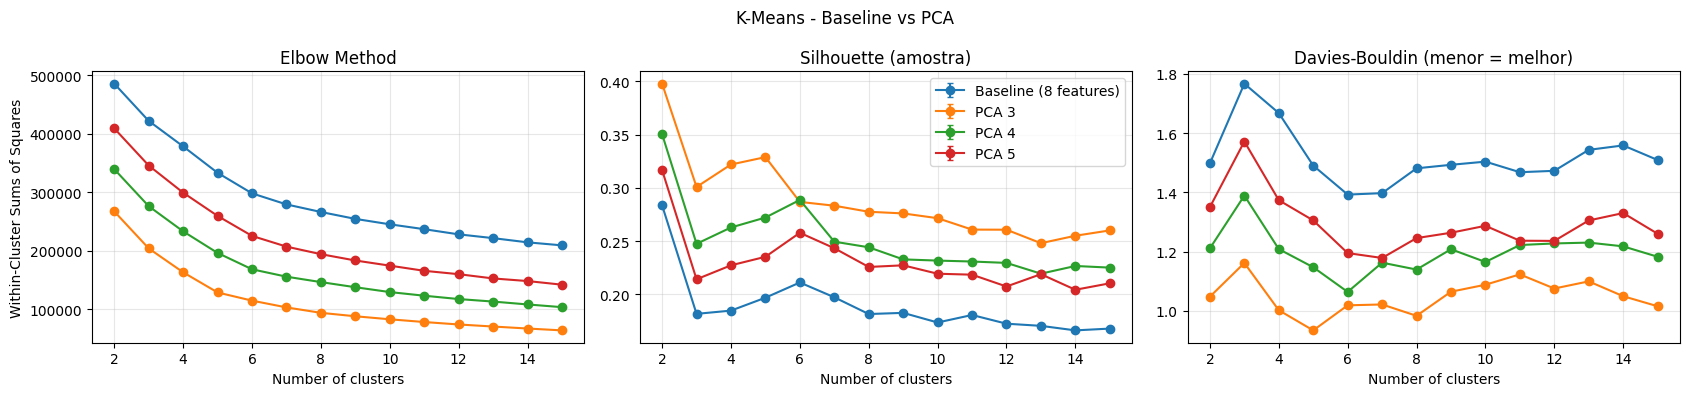

In [13]:
res = pd.concat([varrer_k(X_modelo, nome) for nome, X_modelo in espacos.items()], ignore_index=True)

plot_varredura(res, "K-Means - Baseline vs PCA")

#### Resultados da varredura

Nesta execução, o maior Silhouette da varredura aparece em k=2, especialmente nos espaços PCA. Isso não determina sozinho a escolha: valores de k maiores também são avaliados para obter clusters mais específicos e interpretáveis. A decisão considera o elbow, o Davies-Bouldin, as métricas no espaço original e a diversidade de gêneros.

## Comparação dos Modelos

Cada modelo é treinado com os valores de k escolhidos e todas as métricas são calculadas na mesma tabela. O valor de `K_COMPARACAO` pode ser alterado para testar outros k.

### Performance Metrics

In [14]:
K_COMPARACAO = [4, n_clusters]


X_base = espacos[NOME_BASELINE]


comparacao_kmeans = comparar_kmeans(espacos, K_COMPARACAO, res)
comparacao_kmeans.round(3)

,espaco,k,silhouette,silhouette_8d,davies_bouldin,davies_bouldin_8d,maior_cluster_pct,menor_cluster_pct,genero_dominante_pct,entropia_generos
0,Baseline (8 features),4,0.185,0.185,1.668,1.668,36.821,8.217,3.528,0.912
1,Baseline (8 features),6,0.211,0.211,1.393,1.393,29.103,6.924,4.670,0.889
2,PCA 3,4,0.322,0.188,1.003,1.586,40.766,7.893,3.329,0.924
3,PCA 3,6,0.287,0.144,1.019,1.756,24.801,7.197,4.509,0.901
4,PCA 4,4,0.263,0.189,1.209,1.574,40.458,7.567,3.288,0.925
5,PCA 4,6,0.289,0.200,1.064,1.436,30.416,6.957,4.477,0.896
6,PCA 5,4,0.227,0.190,1.374,1.566,39.847,7.462,3.302,0.924
7,PCA 5,6,0.258,0.210,1.195,1.394,29.830,6.896,4.677,0.889


#### Resultados da comparação

Nesta execução, o PCA 3 com k=4 apresenta o melhor Silhouette no espaço reduzido. Porém, ao avaliar os rótulos no espaço original de oito features, sua vantagem em relação ao baseline k=4 é pequena. Para k=6, o baseline apresenta resultados ligeiramente melhores ou muito próximos aos espaços PCA nas métricas calculadas no espaço original. As métricas de diversidade de gêneros são semelhantes entre as alternativas; portanto, a escolha deve considerar também a distribuição e a interpretação dos perfis.

### Perfil dos Clusters

A escolha final também considera a interpretabilidade. A tabela e os gráficos mostram as médias das features originais por cluster, permitindo comparar os perfis entre os modelos.

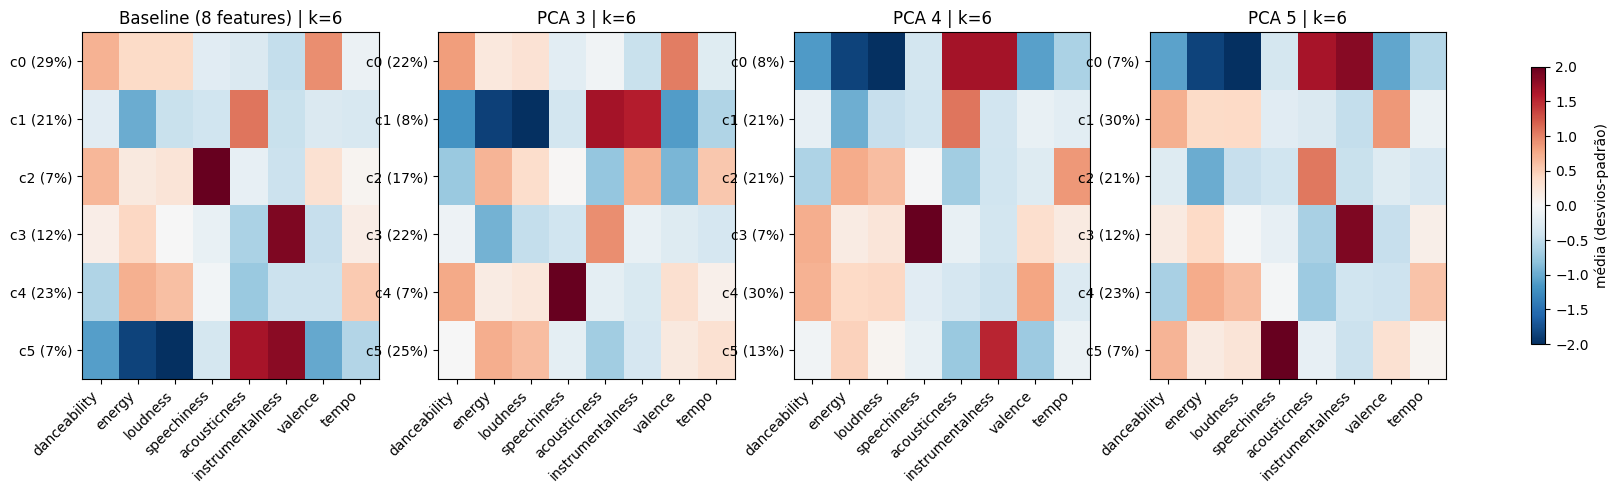


Baseline (8 features) | k=6


,pct_musicas,top_generos
cluster,,
0,29.1,"salsa, forro, pagode"
1,20.9,"tango, honky-tonk, cantopop"
2,6.9,"j-dance, dancehall, funk"
3,12.3,"minimal-techno, detroit-techno, techno"
4,23.4,"metalcore, heavy-metal, death-metal"
5,7.3,"new-age, ambient, classical"



PCA 3 | k=6


,pct_musicas,top_generos
cluster,,
0,21.8,"salsa, forro, pagode"
1,7.7,"new-age, ambient, classical"
2,16.6,"grindcore, black-metal, death-metal"
3,22.0,"tango, honky-tonk, cantopop"
4,7.2,"j-dance, dancehall, funk"
5,24.8,"j-idol, punk-rock, heavy-metal"



PCA 4 | k=6


,pct_musicas,top_generos
cluster,,
0,7.7,"new-age, ambient, classical"
1,21.1,"tango, honky-tonk, cantopop"
2,21.1,"metalcore, heavy-metal, hardstyle"
3,7.0,"j-dance, dancehall, funk"
4,30.4,"forro, salsa, disco"
5,12.7,"minimal-techno, detroit-techno, grindcore"



PCA 5 | k=6


,pct_musicas,top_generos
cluster,,
0,7.3,"new-age, ambient, classical"
1,29.8,"forro, salsa, disco"
2,20.9,"tango, honky-tonk, cantopop"
3,12.0,"minimal-techno, detroit-techno, techno"
4,23.0,"metalcore, heavy-metal, death-metal"
5,6.9,"j-dance, dancehall, funk"


In [15]:
K_PERFIL = n_clusters


fig, axes = plt.subplots(1, len(espacos), figsize=(5.5 * len(espacos), 4.5))
perfis = {}

for ax, nome in zip(axes, espacos):
    labels = pd.Series(modelos_kmeans[(nome, K_PERFIL)], index=df_metadata.index)
    perfis[nome] = perfil_clusters(labels)
    im = plot_perfil(perfis[nome], f"{nome} | k={K_PERFIL}", ax)

fig.colorbar(im, ax=axes, shrink=0.8, label="média (desvios-padrão)")
plt.show()



for nome, perfil in perfis.items():
    print(f"\n{nome} | k={K_PERFIL}")
    display(perfil[["pct_musicas", "top_generos"]].round(1))

#### Resultados do perfil

Nesta execução, o baseline com k=6 apresenta grupos com perfis de gêneros relativamente fáceis de interpretar: aparecem agrupamentos associados, por exemplo, a salsa/forró/pagode, tango/honky-tonk/cantopop, techno, metal e ambient/clássica. Os espaços PCA também formam grupos com gêneros relacionados, mas reorganizam algumas dessas combinações. Use os heatmaps e a distribuição dos tamanhos para avaliar se essa separação faz sentido para a proposta de descoberta musical.

### Visualização dos Clusters

Os modelos são exibidos na mesma projeção PCA em duas dimensões para facilitar a comparação visual dos agrupamentos.

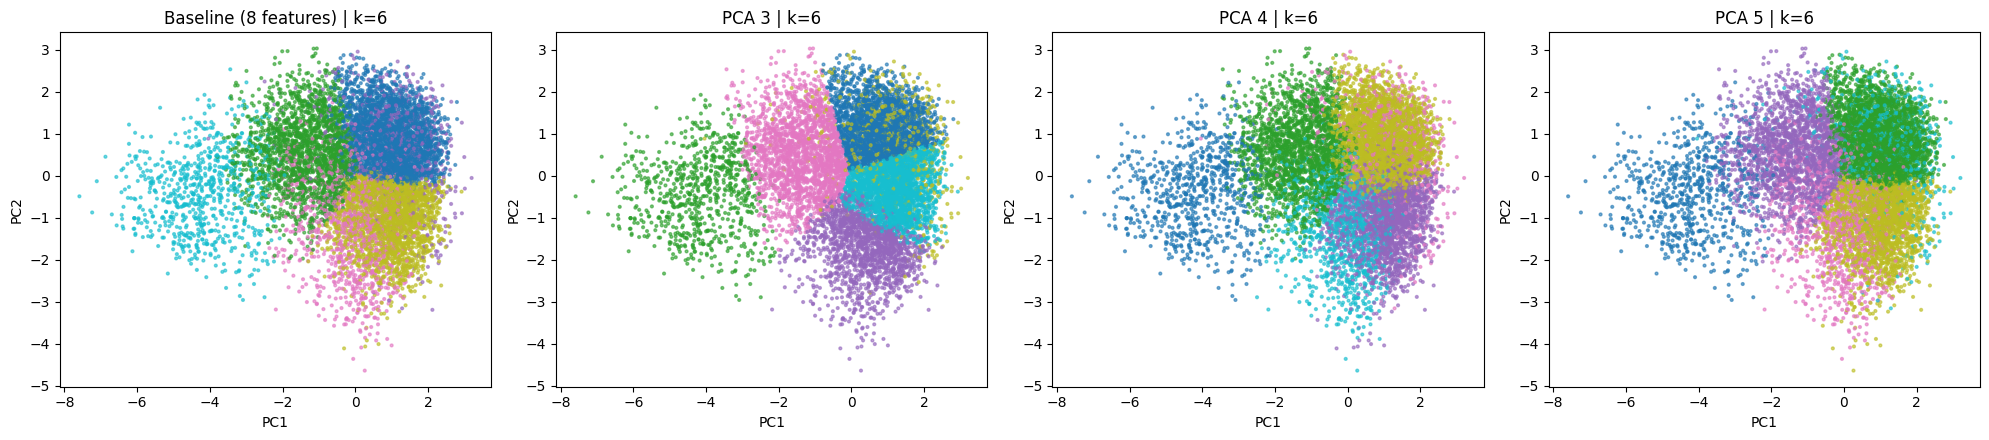

In [16]:
pcs_2d = pca_full.transform(X_scaled)[:, :2]



rng = np.random.RandomState(42)
idx_plot = rng.choice(len(X_scaled), size=min(10000, len(X_scaled)), replace=False)


fig, axes = plt.subplots(1, len(espacos), figsize=(5 * len(espacos), 4.5))

for ax, nome in zip(axes, espacos):
    plot_pc12(idx_plot, modelos_kmeans[(nome, K_PERFIL)][idx_plot], f"{nome} | k={K_PERFIL}", ax)

plt.tight_layout()
plt.show()

## Conclusão

Com base nos resultados desta execução, o **baseline com k=6** foi mantido como modelo final. Embora o PCA 3 com k=4 tenha apresentado o maior Silhouette no espaço reduzido, essa vantagem não se mantém de forma relevante quando os agrupamentos são avaliados no espaço original. Para k=6, o baseline tem métricas originais ligeiramente melhores ou muito próximas às alternativas PCA e apresenta perfis de gêneros interpretáveis.

A escolha prioriza, portanto, o equilíbrio entre separação no espaço original, diversidade de gêneros e interpretabilidade, e não o maior valor isolado de Silhouette. O modelo final é treinado novamente na seção **Train**.

# Train

Treina o K-Means final no baseline com o número de clusters selecionado. O treinamento final usa `n_init=10`, enquanto a varredura usa `n_init=5` para reduzir o tempo de execução.

In [17]:
model = KMeans(n_clusters=n_clusters, n_init=10, random_state=42)
model.fit(X_scaled)

,n_clusters,6
,init,'k-means++'
,n_init,10
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [18]:
os.makedirs('../artifacts/kmeans', exist_ok=True)
joblib.dump(model, "../artifacts/kmeans/kmeans_model.joblib")

['../artifacts/kmeans/kmeans_model.joblib']

# Assign tracks to clusters

In [19]:
X = np.asarray(X_scaled)


labels = model.predict(X)

print(X.shape)
print(labels.shape)

(80175, 8)
(80175,)


# Build input tracks list

In [20]:
genre = "jazz"


input_tracks = df_metadata[df_metadata["genres"].map(lambda g: genre in g)].sample(
    n=input_size,
    random_state=42
)

In [21]:
input_tracks[['track_id', 'artists', 'track_name', 'genres']]

,track_id,artists,track_name,genres
49046,5hyJ1GbE8vZL1BGKE1MSPJ,Tulus,Merdu Untukmu - Outro,[jazz]
12597,5fqDXVrqZRCtyOVFQBONc6,Konteks,Backdrop,"[chill, jazz]"
48275,2etqMd6kibMrZoPCPd2fMi,Robert Broberg,Mitt lilla fejs & jag,"[j-pop, jazz, swedish]"
48056,5iLvprNgPn14wije5V6djv,Robert Broberg,Vatten,"[j-pop, jazz, swedish]"
48333,2MKLbFPQ3QDXpQ0KnS06Kl,Norah Jones,Those Sweet Words,"[j-pop, jazz]"


In [22]:
input_indices = input_tracks.index.to_list()

In [23]:
playlist_id = spo.create_playlist(token)
spo.add_tracks_to_playlist(token, playlist_id, df_metadata.iloc[input_indices]['track_id'])
spo.display_player(playlist_id)

# Recommend

1. Calcula o perfil das músicas de entrada (média das features escaladas)
2. Identifica o cluster do perfil
3. Ordena as músicas desse cluster pela distância euclidiana ao perfil, ignorando as músicas de entrada

In [24]:
input_profile = X[input_indices].mean(axis=0).reshape(1, -1)


cluster = model.predict(input_profile)[0]


candidates = np.where(labels == cluster)[0]
candidates = candidates[~np.isin(candidates, input_indices)]


all_distances = np.linalg.norm(X[candidates] - input_profile, axis=1)
order = np.argsort(all_distances)[:output_size]


distances = all_distances[order].reshape(1, -1)
indices = candidates[order].reshape(1, -1)

In [25]:
playlist_id = spo.create_playlist(token)
spo.add_tracks_to_playlist(token, playlist_id, df_metadata.iloc[indices[0]]['track_id'])
spo.display_player(playlist_id)

In [26]:
recommendations = df_metadata.iloc[indices[0]]
recommendations[['track_id', 'artists', 'track_name', 'genres']]

,track_id,artists,track_name,genres
54349,6Dc2tCivms1s2X9myWe4ni,Rodrigo Amarante,Tuyo (Narcos Theme) - A Netflix Original Serie...,[mpb]
64770,1nLr4BPL8q1w7OgUHk4mSQ,Alberto Vazquez,Encarcelamiento,[rock-n-roll]
75292,2uUlt61KHLLEvJaDn72V6w,Adriana Varela,Anclao en París,[tango]
1429,50OIIM4GNp5iidK4fPlthO,Jorge Drexler,Al Otro Lado Del Río (342 Amazônia ao Vivo no ...,[afrobeat]
43618,4RzpaDRpNI2JZQ8LtAC05x,Vismay Patel,Baarish Mein,"[indian, singer-songwriter, songwriter]"
194,6huS9u0BDfeQHq0lObNLPl,Us The Duo,Better Together,[acoustic]
15464,1CfnMFQtuay15XHlNGpCQa,Roger Miller,King Of The Road - Single Version,[country]
9647,2EL6VBbIx8xmGQVRSnQYpY,Lianne La Havas,Paper Thin,"[british, r-n-b, soul]"
25584,1Znlc3UZAbSodFaMBjdpsX,XXXTENTACION,love yourself (interlude),[emo]
28709,0KUu1mcqWylcOhp92A7nSa,Lonely Night;Lost Dreamers,Control Of Me,[french]
